In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pointbiserialr

cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")

print(cdc_survey_data.head())

     State     Sex GeneralHealth  PhysicalHealthDays  MentalHealthDays  \
0  Alabama  Female     Very good                   4                 0   
1  Alabama    Male     Very good                   0                 0   
2  Alabama    Male     Very good                   0                 0   
3  Alabama  Female          Fair                   5                 0   
4  Alabama  Female          Good                   3                15   

                                     LastCheckupTime PhysicalActivities  \
0  Within past year (anytime less than 12 months ...                Yes   
1  Within past year (anytime less than 12 months ...                Yes   
2  Within past year (anytime less than 12 months ...                 No   
3  Within past year (anytime less than 12 months ...                Yes   
4  Within past year (anytime less than 12 months ...                Yes   

   SleepHours            RemovedTeeth HadHeartAttack  ... HeightInMeters  \
0           9            Non

In [3]:
raw = cdc_survey_data.copy()

In [4]:
df = pd.get_dummies(cdc_survey_data, drop_first=True)
df

,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI,State_Alaska,State_Arizona,State_Arkansas,State_California,...,AlcoholDrinkers_Yes,HIVTesting_Yes,FluVaxLast12_Yes,PneumoVaxEver_Yes,"TetanusLast10Tdap_Yes, received Tdap","TetanusLast10Tdap_Yes, received tetanus shot but not sure what type","TetanusLast10Tdap_Yes, received tetanus shot, but not Tdap",HighRiskLastYear_Yes,CovidPos_Tested positive using home test without a health professional,CovidPos_Yes
0,4,0,9,1.60,71.67,27.99,False,False,False,False,...,False,False,True,True,True,False,False,False,False,False
1,0,0,6,1.78,95.25,30.13,False,False,False,False,...,False,False,True,True,False,True,False,False,False,False
2,0,0,8,1.85,108.86,31.66,False,False,False,False,...,True,False,False,True,False,False,False,False,False,True
3,5,0,9,1.70,90.72,31.32,False,False,False,False,...,False,False,True,True,False,False,False,False,False,True
4,3,15,5,1.55,79.38,33.07,False,False,False,False,...,False,False,True,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246017,0,0,6,1.78,102.06,32.28,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False
246018,0,7,7,1.93,90.72,24.34,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
246019,0,15,7,1.68,83.91,29.86,False,False,False,False,...,True,True,True,True,False,True,False,False,False,True
246020,2,2,7,1.70,83.01,28.66,False,False,False,False,...,False,True,True,False,False,True,False,False,False,False


In [5]:
# Random Forest
cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

from sklearn.model_selection import train_test_split

predictors_train, predictors_test, target_train, target_test = train_test_split(predictors, target, test_size=0.2, random_state=42)#80/20 training test split

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100,class_weight='balanced', random_state=42)
model.fit(predictors_train, target_train)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

target_pred = model.predict(predictors_test)

print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

Accuracy: 0.9483182603393964
Confusion Matrix:
 [[46372   201]
 [ 2342   290]]
Classification Report:
               precision    recall  f1-score   support

       False       0.95      1.00      0.97     46573
        True       0.59      0.11      0.19      2632

    accuracy                           0.95     49205
   macro avg       0.77      0.55      0.58     49205
weighted avg       0.93      0.95      0.93     49205



In [11]:
#CFS (Correlation-based Feature Selection) Subset Evaluation
#Subset Generation: Best-First Search (BFS)
#Subset Evaluation: CFS (Correlation-based Feature Selection)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pointbiserialr
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from itertools import combinations

# Load & Encode Data
cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")


cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']

# CFS + BFS Feature Selection

def compute_correlations(predictors, target):
    feature_names = predictors.columns.tolist()
    n = len(feature_names)

    
    relevance = {}
    for feat in feature_names:
        r, _ = pointbiserialr(predictors[feat], target)
        relevance[feat] = abs(r)

    # Feature-feature redundancy matrix: |r(fi, fj)|
    redundancy = pd.DataFrame(np.zeros((n, n)), index=feature_names, columns=feature_names)
    for i, f1 in enumerate(feature_names):
        for j, f2 in enumerate(feature_names):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(predictors[f1], predictors[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r

    
    return relevance, redundancy


def cfs_merit(subset, relevance, redundancy):
    
    # Merit = (k * avg_relevance) / sqrt(k + k*(k-1) * avg_redundancy)

    k = len(subset)
    if k == 0:
        return 0.0

   
    avg_relevance = np.mean([relevance[f] for f in subset])

    if k == 1:
        avg_redundancy = 0.0
    else:
        pair_redunds = [
            redundancy.loc[f1, f2]
            for f1, f2 in combinations(subset, 2)
        ]
        avg_redundancy = np.mean(pair_redunds)


    denominator = np.sqrt(k + k * (k - 1) * avg_redundancy)
    if denominator == 0:
        return 0.0

    merit = (k * avg_relevance) / denominator
    return merit


def bfs_cfs(predictors, target, max_features=None):
    #Balances Revlence and Reducency

    relevance, redundancy = compute_correlations(predictors, target)
    all_features = predictors.columns.tolist()

    if max_features is None:
        max_features = len(all_features)

    current_subset = []
    current_merit = 0.0
    visited = set()
    visited.add(frozenset(current_subset))

    
    iteration = 0

    while True:
        iteration += 1
        best_neighbour = None
        best_merit = current_merit
  
        neighbours = []

        # Add one feature 
        for feat in all_features:
            if feat not in current_subset:
                if len(current_subset) < max_features:
                    neighbour = current_subset + [feat]
                    neighbours.append(neighbour)

        # Remove one feature 
        for feat in current_subset:
            neighbour = [f for f in current_subset if f != feat]
            neighbours.append(neighbour)

        # evaluate neighbours
        for neighbour in neighbours:
            frozen = frozenset(neighbour)
            if frozen in visited:
                continue
            visited.add(frozen)

            merit = cfs_merit(neighbour, relevance, redundancy)
            if merit > best_merit:
                best_merit = merit
                best_neighbour = neighbour

        if best_neighbour is None:
            print(f"Converged at iteration {iteration}. No improvement found.")
            break

        current_subset = best_neighbour
        current_merit = best_merit
        print(f"  Iter {iteration}: {len(current_subset)} features selected | Merit = {current_merit:.4f}")

    
    return current_subset, current_merit


# Run BFS+CFS
selected_features, final_merit = bfs_cfs(predictors, target)

print("\nSelected Features:")
for f in selected_features:
    print(f"  - {f}")
print(f"Final CFS Merit Score: {final_merit:.4f}")

# Random Forest
predictors_selected = predictors[selected_features]

predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors_selected, target, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(predictors_train, target_train)

target_pred = model.predict(predictors_test)

print("\n── Random Forest Results (CFS+BFS Selected Features) ──")
print("Accuracy:        ", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

  Iter 1: 1 features selected | Merit = 0.4459
Converged at iteration 2. No improvement found.

Selected Features:
  - HadAngina_Yes
Final CFS Merit Score: 0.4459

── Random Forest Results (CFS+BFS Selected Features) ──
Accuracy:         0.9399044812519053
Confusion Matrix:
 [[44947  1626]
 [ 1331  1301]]
Classification Report:
               precision    recall  f1-score   support

       False       0.97      0.97      0.97     46573
        True       0.44      0.49      0.47      2632

    accuracy                           0.94     49205
   macro avg       0.71      0.73      0.72     49205
weighted avg       0.94      0.94      0.94     49205



In [13]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
from itertools import combinations
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")
cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']



def cfs_merit(subset, relevance, redundancy, beta=0.3):
    k = len(subset)
    if k == 0:
        return 0.0

    avg_relevance = np.mean([relevance[f] for f in subset])

    if k == 1:
        avg_redundancy = 0.0
    else:
        pair_redunds = [
            redundancy.loc[f1, f2]
            for f1, f2 in combinations(subset, 2)
        ]
        avg_redundancy = np.mean(pair_redunds)

    denominator = np.sqrt(k + beta * k * (k - 1) * avg_redundancy)
    if denominator == 0:
        return 0.0

    return (k * avg_relevance) / denominator



def compute_correlations(predictors, target):
    feature_names = predictors.columns.tolist()
    n = len(feature_names)
    print("Pre-computing correlations...")

    relevance = {}
    for feat in feature_names:
        r, _ = pointbiserialr(predictors[feat], target)
        relevance[feat] = abs(r)

    redundancy = pd.DataFrame(
        np.zeros((n, n)),
        index=feature_names,
        columns=feature_names
    )
    for i, f1 in enumerate(feature_names):
        for j, f2 in enumerate(feature_names):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(predictors[f1], predictors[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r

    print("Correlations computed.")
    return relevance, redundancy



def bfs_cfs(predictors, target, min_features=15, max_features=30):
    relevance, redundancy = compute_correlations(predictors, target)
    all_features = predictors.columns.tolist()

    
    ranked_features = sorted(all_features, key=lambda f: relevance[f], reverse=True)

    current_subset = []
    current_merit = 0.0
    visited = set()
    visited.add(frozenset(current_subset))

    print("\nStarting Best-First Search...")
    iteration = 0

    while len(current_subset) < max_features:
        iteration += 1
        best_neighbour = None
        best_merit = -np.inf  # always look for best even if lower than current

        # ── Generate neighbours ──
        neighbours = []
        for feat in all_features:
            if feat not in current_subset:
                neighbours.append(current_subset + [feat])
        for feat in current_subset:
            neighbours.append([f for f in current_subset if f != feat])

        # ── Evaluate neighbours ──
        improved = False
        for neighbour in neighbours:
            frozen = frozenset(neighbour)
            if frozen in visited:
                continue
            visited.add(frozen)

            merit = cfs_merit(neighbour, relevance, redundancy)
            if merit > best_merit:
                best_merit = merit
                best_neighbour = neighbour
                if merit > current_merit:
                    improved = True

        # ── No unvisited neighbours at all ──
        if best_neighbour is None:
            print(f"  All neighbours visited. Stopping at {len(current_subset)} features.")
            break

        # ── Merit improved — always move ──
        if improved or len(current_subset) < min_features:
            current_subset = best_neighbour
            current_merit = best_merit
            status = "improved" if improved else "forced"
            print(f"  Iter {iteration} [{status}]: {len(current_subset)} features | Merit = {current_merit:.4f} | Last added: {current_subset[-1] if len(current_subset) > 0 else 'none'}")
        else:
            # Merit converged and min_features reached — stop
            print(f"  Converged at {len(current_subset)} features.")
            break

    print(f"\nBFS-CFS selected {len(current_subset)} features.")
    return current_subset, current_merit



selected_features, final_merit = bfs_cfs(predictors, target, min_features=15, max_features=30)

print("\nSelected Features:")
for f in selected_features:
    print(f"  - {f}")
print(f"Final CFS Merit Score: {final_merit:.4f}")

# Random Forest
predictors_selected = predictors[selected_features]

predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors_selected, target, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(predictors_train, target_train)

target_pred = model.predict(predictors_test)

print("\n── Random Forest Results (CFS+BFS Selected Features) ──")
print("Accuracy:        ", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

Pre-computing correlations...
Correlations computed.

Starting Best-First Search...
  Iter 1 [improved]: 1 features | Merit = 0.4459 | Last added: HadAngina_Yes
  Iter 2 [forced]: 2 features | Merit = 0.4308 | Last added: HadStroke_Yes
  Iter 3 [improved]: 3 features | Merit = 0.4364 | Last added: ChestScan_Yes
  Iter 4 [improved]: 4 features | Merit = 0.4427 | Last added: DifficultyWalking_Yes
  Iter 5 [improved]: 5 features | Merit = 0.4482 | Last added: HadDiabetes_Yes
  Iter 6 [improved]: 6 features | Merit = 0.4518 | Last added: GeneralHealth_Poor
  Iter 7 [improved]: 7 features | Merit = 0.4546 | Last added: RemovedTeeth_All
  Iter 8 [improved]: 8 features | Merit = 0.4574 | Last added: HadCOPD_Yes
  Iter 9 [improved]: 9 features | Merit = 0.4591 | Last added: PneumoVaxEver_Yes
  Iter 10 [improved]: 10 features | Merit = 0.4602 | Last added: HadKidneyDisease_Yes
  Iter 11 [improved]: 11 features | Merit = 0.4621 | Last added: RemovedTeeth_None of them
  Iter 12 [improved]: 12 fea

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from itertools import combinations


cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)

X = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
y = cdc_encoded['HadHeartAttack_Yes']


def compute_correlations(X, y):
    features = X.columns.tolist()

    # relevance to target
    relevance = {}
    for f in features:
        r, _ = pointbiserialr(X[f], y)
        relevance[f] = abs(r)

    # redundancy matrix
    redundancy = pd.DataFrame(np.zeros((len(features), len(features))),
                               index=features, columns=features)

    for i, f1 in enumerate(features):
        for j, f2 in enumerate(features):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(X[f1], X[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r

    return relevance, redundancy


def cfs_merit(subset, relevance, redundancy):
    k = len(subset)
    if k == 0:
        return 0

    avg_rel = np.mean([relevance[f] for f in subset])

    if k == 1:
        avg_red = 0
    else:
        pair_red = [
            redundancy.loc[f1, f2]
            for f1, f2 in combinations(subset, 2)
        ]
        avg_red = np.mean(pair_red)

    # SOFTEN REDUNDANCY IMPACT
    avg_red *= 0.5

    denom = np.sqrt(k + k * (k - 1) * avg_red)
    return (k * avg_rel) / denom if denom != 0 else 0


def bfs_cfs_loose(X, y):
    relevance, redundancy = compute_correlations(X, y)
    features = X.columns.tolist()

    # START with best single feature (important fix)
    start = max(relevance, key=relevance.get)
    current_subset = [start]
    current_merit = cfs_merit(current_subset, relevance, redundancy)

    visited = set()
    visited.add(frozenset(current_subset))

    MIN_FEATURES = 6
    TOLERANCE = 0.002

    iteration = 0

    while True:
        iteration += 1
        best_subset = None
        best_merit = current_merit

        neighbors = []

        # ADD one feature
        for f in features:
            if f not in current_subset:
                neighbors.append(current_subset + [f])

        # REMOVE one feature
        for f in current_subset:
            neighbors.append([x for x in current_subset if x != f])

        improved = False

        for n in neighbors:
            key = frozenset(n)
            if key in visited:
                continue
            visited.add(key)

            m = cfs_merit(n, relevance, redundancy)

            # LOOSER ACCEPTANCE RULE
            if m > best_merit + TOLERANCE:
                best_merit = m
                best_subset = n
                improved = True

        # STOP ONLY IF stuck AND enough features
        if not improved:
            if len(current_subset) >= MIN_FEATURES:
                print(f"Converged at iteration {iteration}")
                break
            else:
                # force expansion if too small
                best_subset = neighbors[0]
                best_merit = cfs_merit(best_subset, relevance, redundancy)

        current_subset = best_subset
        current_merit = best_merit

        print(f"Iter {iteration}: {len(current_subset)} features | Merit={current_merit:.4f}")

    return current_subset, current_merit



selected_features, final_merit = bfs_cfs_loose(X, y)

print("\nSelected Features:")
for f in selected_features:
    print(" -", f)

print("Final Merit:", final_merit)



X_sel = X[selected_features]

X_train, X_test, y_train, y_test = train_test_split(
    X_sel, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict(X_test)


print("\n--- Results ---")
print("Accuracy:", accuracy_score(y_test, pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred))
print("\nReport:\n", classification_report(y_test, pred))

#softer stopping rule
#tolerance for merit improvement
#reduced redundancy penalty
#forced minimum subset size 


# *ADD testing of diffrent reducancy penalty, create acc graoh, false ostive graoh 
# Check doctor selected fatutres 

# TRY STRATIFED SAMOLES Stratified (class-preserving) splits → more reliable evaluation 4.3.26

C:\Users\yusuf\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Iter 1: 2 features | Merit=0.3952
Iter 2: 3 features | Merit=0.4085
Iter 3: 4 features | Merit=0.4161
Iter 4: 3 features | Merit=0.4244
Iter 5: 4 features | Merit=0.4161
Iter 6: 5 features | Merit=0.3769
Iter 7: 6 features | Merit=0.3887
Iter 8: 7 features | Merit=0.3944
Iter 9: 6 features | Merit=0.4203
Converged at iteration 10

Selected Features:
 - HadAngina_Yes
 - HadStroke_Yes
 - ChestScan_Yes
 - PhysicalHealthDays
 - HadDiabetes_Yes
 - RemovedTeeth_All
Final Merit: 0.4203006866622381

--- Results ---
Accuracy: 0.8540392236561325

Confusion Matrix:
 [[40234  6339]
 [  843  1789]]

Report:
               precision    recall  f1-score   support

       False       0.98      0.86      0.92     46573
        True       0.22      0.68      0.33      2632

    accuracy                           0.85     49205
   macro avg       0.60      0.77      0.63     49205
weighted avg       0.94      0.85      0.89     49205



C:\Users\yusuf\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Computing correlations...
Running sweep...
  red_weight=0.00 | merit=0.6253 | features=22
  red_weight=0.05 | merit=0.5819 | features=20
  red_weight=0.10 | merit=0.5476 | features=17
  red_weight=0.15 | merit=0.5241 | features=17
  red_weight=0.20 | merit=0.4997 | features=15
  red_weight=0.25 | merit=0.4835 | features=15
  red_weight=0.30 | merit=0.4653 | features=13
  red_weight=0.35 | merit=0.4411 | features=7
  red_weight=0.40 | merit=0.4391 | features=7
  red_weight=0.45 | merit=0.4257 | features=6
  red_weight=0.50 | merit=0.4203 | features=6
  red_weight=0.55 | merit=0.4194 | features=6
  red_weight=0.60 | merit=0.4101 | features=6
  red_weight=0.65 | merit=0.4052 | features=6
  red_weight=0.70 | merit=0.4006 | features=6
  red_weight=0.75 | merit=0.3961 | features=6
  red_weight=0.80 | merit=0.3917 | features=6
  red_weight=0.85 | merit=0.3875 | features=6
  red_weight=0.90 | merit=0.3834 | features=6
  red_weight=0.95 | merit=0.3794 | features=6
  red_weight=1.00 | merit=0.37

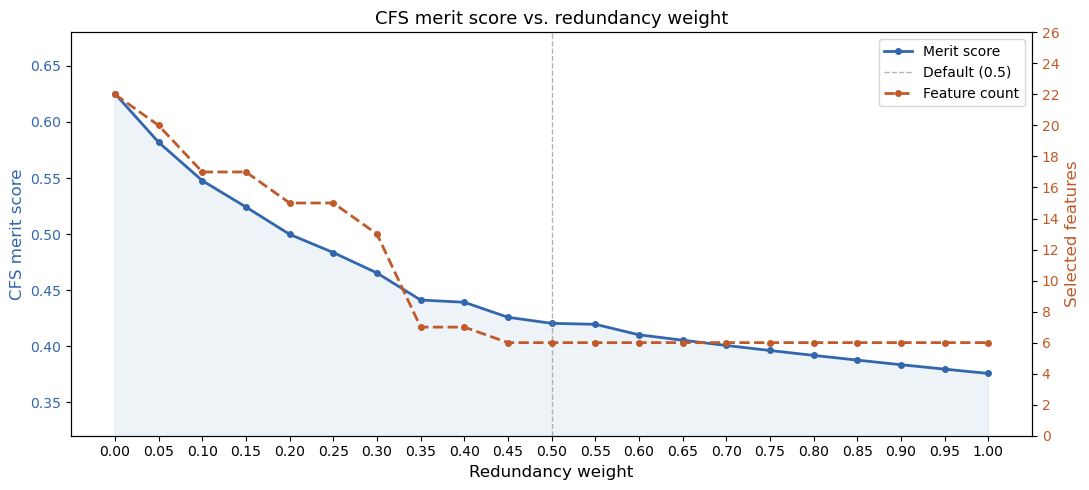

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
from itertools import combinations
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")
cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
X = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
y = cdc_encoded['HadHeartAttack_Yes']



def compute_correlations(X, y):
    features = X.columns.tolist()

    relevance = {}
    for f in features:
        r, _ = pointbiserialr(X[f], y)
        relevance[f] = abs(r)

    redundancy = pd.DataFrame(
        np.zeros((len(features), len(features))),
        index=features, columns=features
    )
    for i, f1 in enumerate(features):
        for j, f2 in enumerate(features):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(X[f1], X[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r

    return relevance, redundancy



def cfs_merit(subset, relevance, redundancy, red_weight):
    k = len(subset)
    if k == 0:
        return 0
    avg_rel = np.mean([relevance[f] for f in subset])
    if k == 1:
        avg_red = 0
    else:
        pair_red = [redundancy.loc[f1, f2] for f1, f2 in combinations(subset, 2)]
        avg_red = np.mean(pair_red)
    avg_red *= red_weight
    denom = np.sqrt(k + k * (k - 1) * avg_red)
    return (k * avg_rel) / denom if denom != 0 else 0


def bfs_cfs(X, relevance, redundancy, red_weight):
    features = X.columns.tolist()
    start = max(relevance, key=relevance.get)
    current_subset = [start]
    current_merit = cfs_merit(current_subset, relevance, redundancy, red_weight)
    visited = {frozenset(current_subset)}
    MIN_FEATURES = 6
    TOLERANCE = 0.002

    for _ in range(200):
        neighbors = []
        for f in features:
            if f not in current_subset:
                neighbors.append(current_subset + [f])
        for f in current_subset:
            neighbors.append([x for x in current_subset if x != f])

        best_subset, best_merit, improved = None, current_merit, False
        for n in neighbors:
            key = frozenset(n)
            if key in visited:
                continue
            visited.add(key)
            m = cfs_merit(n, relevance, redundancy, red_weight)
            if m > best_merit + TOLERANCE:
                best_merit, best_subset, improved = m, n, True

        if not improved:
            if len(current_subset) >= MIN_FEATURES:
                break
            else:
                best_subset = neighbors[0]
                best_merit = cfs_merit(best_subset, relevance, redundancy, red_weight)

        current_subset, current_merit = best_subset, best_merit

    return current_subset, current_merit


print("Computing correlations")
relevance, redundancy = compute_correlations(X, y)
print("Running")

red_values = np.round(np.arange(0.0, 1.05, 0.05), 2)
merits, feature_counts = [], []

for rw in red_values:
    subset, merit = bfs_cfs(X, relevance, redundancy, rw)
    merits.append(merit)
    feature_counts.append(len(subset))
    print(f"  red_weight={rw:.2f} | merit={merit:.4f} | features={len(subset)}")



fig, ax1 = plt.subplots(figsize=(11, 5))

color_merit = "#3266ad"
color_feats = "#c05a2a"

ax1.plot(red_values, merits, color=color_merit, linewidth=2,
         marker='o', markersize=4, label='Merit score')
ax1.fill_between(red_values, merits, alpha=0.08, color=color_merit)
ax1.set_xlabel("Redundancy weight", fontsize=12)
ax1.set_ylabel("CFS merit score", color=color_merit, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_merit)
ax1.set_ylim(0.32, 0.68)
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))


ax1.axvline(x=0.5, color='gray', linewidth=1, linestyle='--', alpha=0.6, label='Default (0.5)')

ax2 = ax1.twinx()
ax2.plot(red_values, feature_counts, color=color_feats, linewidth=2,
         marker='o', markersize=4, linestyle='--', label='Feature count')
ax2.set_ylabel("Selected features", color=color_feats, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_feats)
ax2.set_ylim(0, 26)
ax2.yaxis.set_major_locator(ticker.MultipleLocator(2))


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=10)

plt.title("CFS merit score vs. redundancy weight", fontsize=13)
plt.xticks(red_values, rotation=45, fontsize=9)
plt.tight_layout()
plt.savefig("redundancy_sweep_chart.png", dpi=150)
plt.show()



Computing correlations...
red_weight=0.0 — selecting features... 22 features. Training... acc=91.52%  f1=0.2843
red_weight=0.2 — selecting features... 15 features. Training... acc=88.53%  f1=0.3125
red_weight=0.4 — selecting features... 7 features. Training... acc=80.91%  f1=0.2977
red_weight=0.6 — selecting features... 6 features. Training... acc=85.40%  f1=0.3325
red_weight=0.8 — selecting features... 6 features. Training... acc=85.40%  f1=0.3325
red_weight=1.0 — selecting features... 6 features. Training... acc=85.40%  f1=0.3325


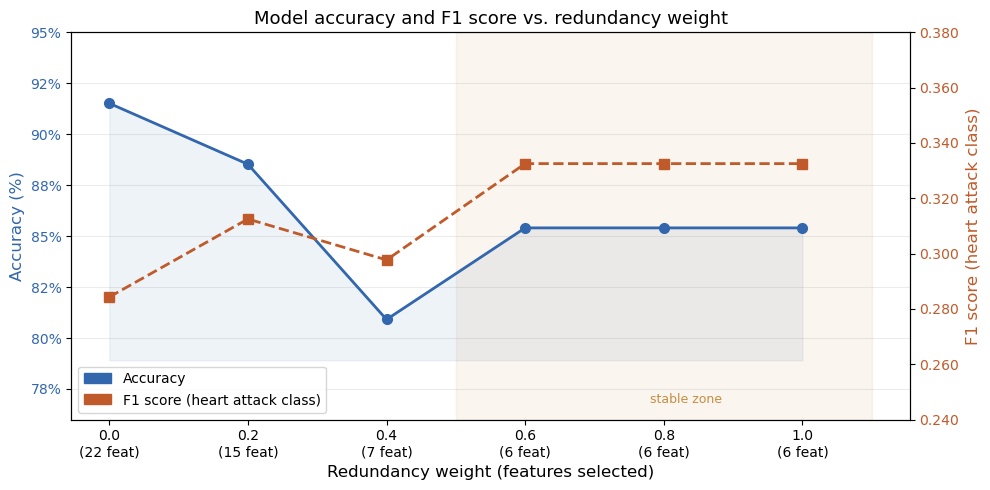

Saved to accuracy_f1_sweep.png


In [2]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
from itertools import combinations
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")
cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
X = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
y = cdc_encoded['HadHeartAttack_Yes']


def compute_correlations(X, y):
    features = X.columns.tolist()
    relevance = {}
    for f in features:
        r, _ = pointbiserialr(X[f], y)
        relevance[f] = abs(r)

    redundancy = pd.DataFrame(
        np.zeros((len(features), len(features))),
        index=features, columns=features
    )
    for i, f1 in enumerate(features):
        for j, f2 in enumerate(features):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(X[f1], X[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r
    return relevance, redundancy


def cfs_merit(subset, relevance, redundancy, red_weight):
    k = len(subset)
    if k == 0:
        return 0
    avg_rel = np.mean([relevance[f] for f in subset])
    if k == 1:
        avg_red = 0
    else:
        pair_red = [redundancy.loc[f1, f2] for f1, f2 in combinations(subset, 2)]
        avg_red = np.mean(pair_red)
    avg_red *= red_weight
    denom = np.sqrt(k + k * (k - 1) * avg_red)
    return (k * avg_rel) / denom if denom != 0 else 0



def bfs_cfs(X, relevance, redundancy, red_weight):
    features = X.columns.tolist()
    start = max(relevance, key=relevance.get)
    current_subset = [start]
    current_merit = cfs_merit(current_subset, relevance, redundancy, red_weight)
    visited = {frozenset(current_subset)}
    MIN_FEATURES = 6
    TOLERANCE = 0.002

    for _ in range(200):
        neighbors = []
        for f in features:
            if f not in current_subset:
                neighbors.append(current_subset + [f])
        for f in current_subset:
            neighbors.append([x for x in current_subset if x != f])

        best_subset, best_merit, improved = None, current_merit, False
        for n in neighbors:
            key = frozenset(n)
            if key in visited:
                continue
            visited.add(key)
            m = cfs_merit(n, relevance, redundancy, red_weight)
            if m > best_merit + TOLERANCE:
                best_merit, best_subset, improved = m, n, True

        if not improved:
            if len(current_subset) >= MIN_FEATURES:
                break
            else:
                best_subset = neighbors[0]
                best_merit = cfs_merit(best_subset, relevance, redundancy, red_weight)

        current_subset, current_merit = best_subset, best_merit

    return current_subset, current_merit


print("Computing ")
relevance, redundancy = compute_correlations(X, y)

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

red_values = np.round(np.arange(0.0, 1.01, 0.2), 2)
accuracies, f1_scores, feature_counts = [], [], []

for rw in red_values:
    print(f"red_weight={rw:.1f} — selecting features...", end=" ")
    subset, _ = bfs_cfs(X, relevance, redundancy, rw)
    print(f"{len(subset)} features. Training...", end=" ")

    model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
    model.fit(X_train_full[subset], y_train)
    pred = model.predict(X_test_full[subset])

    acc = accuracy_score(y_test, pred) * 100
    f1 = f1_score(y_test, pred, pos_label=1)
    accuracies.append(acc)
    f1_scores.append(f1)
    feature_counts.append(len(subset))
    print(f"acc={acc:.2f}%  f1={f1:.4f}")

x = np.arange(len(red_values))
x_labels = [f"{rw:.1f}\n({n} feat)" for rw, n in zip(red_values, feature_counts)]

color_acc = "#3266ad"
color_f1  = "#c05a2a"


fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(x, accuracies, color=color_acc, linewidth=2, marker='o',
         markersize=7, label='Accuracy', zorder=3)
ax1.fill_between(x, accuracies, min(accuracies) - 2, alpha=0.08, color=color_acc)
ax1.set_ylabel("Accuracy (%)", color=color_acc, fontsize=12)
ax1.set_ylim(76, 95)
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))

# Shade stable zone (weight 0.6 onwards = index 3+)
ax1.axvspan(2.5, len(red_values) - 0.5, color='#ba7517', alpha=0.07, zorder=0)
ax1.text(3.9, 76.8, "stable zone", fontsize=9, color='#ba7517', alpha=0.8)

ax2 = ax1.twinx()
ax2.plot(x, f1_scores, color=color_f1, linewidth=2, marker='s',
         markersize=7, linestyle='--', label='F1 score', zorder=3)
ax2.set_ylabel("F1 score (heart attack class)", color=color_f1, fontsize=12)
ax2.set_ylim(0.24, 0.38)
ax2.tick_params(axis='y', labelcolor=color_f1)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.3f}"))

ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, fontsize=10)
ax1.set_xlabel("Redundancy weight (features selected)", fontsize=12)
ax1.grid(axis='y', color='gray', alpha=0.15)

# Legend
acc_patch = mpatches.Patch(color=color_acc, label='Accuracy')
f1_patch  = mpatches.Patch(color=color_f1,  label='F1 score (heart attack class)')
ax1.legend(handles=[acc_patch, f1_patch], loc='lower left', fontsize=10)

plt.title("Model accuracy and F1 score vs. redundancy weight", fontsize=13)
plt.tight_layout()
plt.savefig("accuracy_f1_sweep.png", dpi=150)
plt.show()
print("Saved to accuracy_f1_sweep.png")

In [ ]:
#New Feature Selection Methods (Comoare with current aoorch)
#https://pmc.ncbi.nlm.nih.gov/articles/PMC4480804/
# Working to imolement 

import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
from itertools import combinations
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


cdc_survey_data = pd.read_csv("heart_2022_no_nans.csv")
cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
X = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
y = cdc_encoded['HadHeartAttack_Yes']


def compute_correlations(X, y):
    features = X.columns.tolist()
    relevance = {}
    for f in features:
        r, _ = pointbiserialr(X[f], y)
        relevance[f] = abs(r)

    redundancy = pd.DataFrame(
        np.zeros((len(features), len(features))),
        index=features, columns=features
    )
    for i, f1 in enumerate(features):
        for j, f2 in enumerate(features):
            if i == j:
                redundancy.loc[f1, f2] = 1.0
            elif i < j:
                r = abs(np.corrcoef(X[f1], X[f2])[0, 1])
                redundancy.loc[f1, f2] = r
                redundancy.loc[f2, f1] = r
    return relevance, redundancy


def cfs_merit(subset, relevance, redundancy, red_weight):
    k = len(subset)
    if k == 0:
        return 0
    avg_rel = np.mean([relevance[f] for f in subset])
    if k == 1:
        avg_red = 0
    else:
        pair_red = [redundancy.loc[f1, f2] for f1, f2 in combinations(subset, 2)]
        avg_red = np.mean(pair_red)
    avg_red *= red_weight
    denom = np.sqrt(k + k * (k - 1) * avg_red)
    return (k * avg_rel) / denom if denom != 0 else 0



def bfs_cfs(X, relevance, redundancy, red_weight):
    features = X.columns.tolist()
    start = max(relevance, key=relevance.get)
    current_subset = [start]
    current_merit = cfs_merit(current_subset, relevance, redundancy, red_weight)
    visited = {frozenset(current_subset)}
    MIN_FEATURES = 6
    TOLERANCE = 0.002

    for _ in range(200):
        neighbors = []
        for f in features:
            if f not in current_subset:
                neighbors.append(current_subset + [f])
        for f in current_subset:
            neighbors.append([x for x in current_subset if x != f])

        best_subset, best_merit, improved = None, current_merit, False
        for n in neighbors:
            key = frozenset(n)
            if key in visited:
                continue
            visited.add(key)
            m = cfs_merit(n, relevance, redundancy, red_weight)
            if m > best_merit + TOLERANCE:
                best_merit, best_subset, improved = m, n, True

        if not improved:
            if len(current_subset) >= MIN_FEATURES:
                break
            else:
                best_subset = neighbors[0]
                best_merit = cfs_merit(best_subset, relevance, redundancy, red_weight)

        current_subset, current_merit = best_subset, best_merit

    return current_subset, current_merit


print("Computing ")
relevance, redundancy = compute_correlations(X, y)

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

red_values = np.round(np.arange(0.0, 1.01, 0.2), 2)
accuracies, f1_scores, feature_counts = [], [], []

for rw in red_values:
    print(f"red_weight={rw:.1f} — selecting features...", end=" ")
    subset, _ = bfs_cfs(X, relevance,

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']


# (80/20)
predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)


scaler = StandardScaler()
predictors_train_scaled = scaler.fit_transform(predictors_train)
predictors_test_scaled = scaler.transform(predictors_test)


lasso = LogisticRegression(
    penalty='l1',
    solver='liblinear',   
    C=0.1,                # inverse regularization strength
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lasso.fit(predictors_train_scaled, target_train)


coef = lasso.coef_[0]
selected_mask = coef != 0
selected_features = predictors.columns[selected_mask]

print(f"Number of features before selection: {predictors.shape[1]}")
print(f"Number of features selected by LASSO: {selected_mask.sum()}")
print("\nSelected features and coefficients (sorted by importance):")
coef_df = pd.DataFrame({
    'feature': selected_features,
    'coefficient': coef[selected_mask]
}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df.to_string(index=False))


predictors_train_lasso = predictors_train[selected_features]
predictors_test_lasso = predictors_test[selected_features]


model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
model.fit(predictors_train_lasso, target_train)


target_pred = model.predict(predictors_test_lasso)

print("\n--- Model Performance (LASSO-selected features) ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

Number of features before selection: 121
Number of features selected by LASSO: 119

Selected features and coefficients (sorted by importance):
                                                               feature  coefficient
                                                         HadAngina_Yes     0.622994
                                           AgeCategory_Age 80 or older     0.568504
                                              AgeCategory_Age 70 to 74     0.561350
                                              AgeCategory_Age 65 to 69     0.518041
                                              AgeCategory_Age 75 to 79     0.510155
                                              AgeCategory_Age 60 to 64     0.451409
                                              AgeCategory_Age 55 to 59     0.386656
                                                         ChestScan_Yes     0.345907
                                                              Sex_Male     0.328879
                 

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']


predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42
)

scaler = StandardScaler()
predictors_train_scaled = scaler.fit_transform(predictors_train)
predictors_test_scaled = scaler.transform(predictors_test)


lasso = LogisticRegression(
    penalty='l1',
    solver='liblinear',  
    C=0.001,                
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lasso.fit(predictors_train_scaled, target_train)


coef = lasso.coef_[0]
selected_mask = coef != 0
selected_features = predictors.columns[selected_mask]

print(f"Number of features before selection: {predictors.shape[1]}")
print(f"Number of features selected by LASSO: {selected_mask.sum()}")
print("\nSelected features and coefficients (sorted by importance):")
coef_df = pd.DataFrame({
    'feature': selected_features,
    'coefficient': coef[selected_mask]
}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df.to_string(index=False))


predictors_train_lasso = predictors_train[selected_features]
predictors_test_lasso = predictors_test[selected_features]

model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)
model.fit(predictors_train_lasso, target_train)

target_pred = model.predict(predictors_test_lasso)

print("\n--- Model Performance (LASSO-selected features) ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))

Number of features before selection: 121
Number of features selected by LASSO: 42

Selected features and coefficients (sorted by importance):
                                                               feature  coefficient
                                                         HadAngina_Yes     0.612894
                                                         ChestScan_Yes     0.339533
                                                              Sex_Male     0.244685
                                           AgeCategory_Age 80 or older     0.208231
                                                         HadStroke_Yes     0.196976
                                                    GeneralHealth_Fair     0.177487
                                              AgeCategory_Age 70 to 74     0.155657
                                              AgeCategory_Age 75 to 79     0.153670
                                                    GeneralHealth_Good     0.137824
                  

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, average_precision_score, precision_recall_curve
)
from imblearn.over_sampling import SMOTE

cdc_encoded = pd.get_dummies(cdc_survey_data, drop_first=True)
predictors = cdc_encoded.drop('HadHeartAttack_Yes', axis=1)
target = cdc_encoded['HadHeartAttack_Yes']


predictors_train, predictors_test, target_train, target_test = train_test_split(
    predictors, target, test_size=0.2, random_state=42, stratify=target
)


scaler = StandardScaler()
predictors_train_scaled = scaler.fit_transform(predictors_train)
predictors_test_scaled = scaler.transform(predictors_test)


lasso_cv = LogisticRegressionCV(
    Cs=np.logspace(-4, 1, 20),
    penalty='l1',
    solver='liblinear',
    cv=5,
    scoring='f1',
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)
lasso_cv.fit(predictors_train_scaled, target_train)

print("Best C selected by CV:", lasso_cv.C_[0])

coef = lasso_cv.coef_[0]
selected_mask = coef != 0
selected_features = predictors.columns[selected_mask]

print(f"Number of features before selection: {predictors.shape[1]}")
print(f"Number of features selected by LASSO: {selected_mask.sum()}")
print("\nSelected features and coefficients (sorted by importance):")
coef_df = pd.DataFrame({
    'feature': selected_features,
    'coefficient': coef[selected_mask]
}).sort_values('coefficient', key=abs, ascending=False)
print(coef_df.to_string(index=False))

predictors_train_lasso = predictors_train[selected_features]
predictors_test_lasso = predictors_test[selected_features]


print("\nClass distribution before SMOTE:")
print(target_train.value_counts())

smote = SMOTE(random_state=42)
predictors_train_smote, target_train_smote = smote.fit_resample(
    predictors_train_lasso, target_train
)

print("\nClass distribution after SMOTE:")
print(target_train_smote.value_counts())

model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',   # keep this too — helps even after SMOTE
    random_state=42
)
model.fit(predictors_train_smote, target_train_smote)


target_pred = model.predict(predictors_test_lasso)
probs = model.predict_proba(predictors_test_lasso)[:, 1]

print("\n--- Model Performance (LASSO + SMOTE, default 0.5 threshold) ---")
print("Accuracy:", accuracy_score(target_test, target_pred))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred))
print("Classification Report:\n", classification_report(target_test, target_pred))
print("ROC-AUC:", roc_auc_score(target_test, probs))
print("PR-AUC (average precision):", average_precision_score(target_test, probs))


precision, recall, thresholds = precision_recall_curve(target_test, probs)

# Example: find the threshold that achieves at least 50% recall
target_recall = 0.50
idx = np.argmax(recall >= target_recall)
best_threshold = thresholds[idx] if idx < len(thresholds) else 0.5

print(f"\nThreshold for recall >= {target_recall}: {best_threshold:.3f}")
print(f"  Precision at this threshold: {precision[idx]:.3f}")
print(f"  Recall at this threshold: {recall[idx]:.3f}")

target_pred_adjusted = (probs >= best_threshold).astype(int)

print("\n--- Model Performance (LASSO + SMOTE, tuned threshold) ---")
print("Accuracy:", accuracy_score(target_test, target_pred_adjusted))
print("Confusion Matrix:\n", confusion_matrix(target_test, target_pred_adjusted))
print("Classification Report:\n", classification_report(target_test, target_pred_adjusted))

NameError: name 'cdc_survey_data' is not defined

In [5]:
print(cdc_survey_data.shape)
print(cdc_encoded.shape)
print(predictors_train_scaled.shape)

(246022, 40)
(246022, 122)
(196817, 121)


In [ ]:
# Use 50,000 observations to select the best C
X_lasso_sample, _, y_lasso_sample, _ = train_test_split(
    predictors_train_scaled,
    target_train,
    train_size=50000,
    random_state=42,
    stratify=target_train
)

lasso_cv = LogisticRegressionCV(
    Cs=8,
    penalty='l1',
    solver='liblinear',
    cv=3,
    scoring='f1',
    class_weight='balanced',
    random_state=42,
    max_iter=300
)

print("Finding best C...")
lasso_cv.fit(X_lasso_sample, y_lasso_sample)

print("Best C:", lasso_cv.C_[0])

In [ ]:
Revise 4.8

https://johfischer.com/2021/08/06/correlation-based-feature-selection-in-python-from-scratch/
    
New Feature Selection Methods (Comoare with current aoorch)
https://pmc.ncbi.nlm.nih.gov/articles/PMC4480804/




#Mutal Information , Non Linear
# Measures I(X;Y)=H(Y)−H(Y∣X)  
# uncertainty in Y minus uncertainty in Y after knowing X

In [ ]:
  1. Start with empty subset.
    2. Generate neighbours by adding OR removing one feature.
    3. Evaluate each neighbour with CFS merit.
    4. Move to best neighbour if it improves current merit.
    5. Repeat until no improvement found (convergence).
    
      Best-First Search (BFS) with CFS evaluation.